# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Ratnesh Singh Bhandari
**Roll Number:** AP24110010649
**Date:** 09-10-26

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [ ]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Answer:** The 70/30 split has higher entropy than the 90/10 split. The 70/30 split is more mixed, so it is harder to guess the label correctly.


### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [ ]:
parent_entropy = entropy([8, 6])
left_entropy = entropy([6, 0])
right_entropy = entropy([2, 6])
weighted_child_entropy = (6 / 14) * left_entropy + (8 / 14) * right_entropy
gain = parent_entropy - weighted_child_entropy

print(f'Parent entropy: {parent_entropy:.4f}')
print(f'Left child entropy: {left_entropy:.4f}')
print(f'Right child entropy: {right_entropy:.4f}')
print(f'Weighted child entropy: {weighted_child_entropy:.4f}')
print(f'Information gain: {gain:.4f}')


Parent entropy: 0.9852
Left child entropy: 0.0000
Right child entropy: 0.8113
Weighted child entropy: 0.4636
Information gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [ ]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [ ]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [ ]:
for attribute in ['Outlook', 'Temperature', 'Humidity']:
    print(f'Gain({attribute}): {info_gain(tennis, attribute):.4f}')

root = max(['Outlook', 'Temperature', 'Humidity'], key=lambda a: info_gain(tennis, a))
print('ID3 root:', root)

for value in sorted(tennis[root].unique()):
    subset = tennis[tennis[root] == value]
    print(f'\\nBranch {root} = {value}')
    print('Class counts:', subset['Play'].value_counts().to_dict())
    if subset['Play'].nunique() > 1:
        remaining = [a for a in ['Outlook', 'Temperature', 'Humidity', 'Wind'] if a != root]
        for attribute in remaining:
            print(f'Gain({attribute}): {info_gain(subset, attribute):.4f}')
        next_attribute = max(remaining, key=lambda a: info_gain(subset, a))
        print('Best next split:', next_attribute)
    else:
        print('Pure branch; leaf prediction:', subset['Play'].iloc[0])


Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518
ID3 root: Outlook
\nBranch Outlook = Overcast
Class counts: {'Yes': 4}
Pure branch; leaf prediction: Yes
\nBranch Outlook = Rain
Class counts: {'Yes': 3, 'No': 2}
Gain(Temperature): 0.0200
Gain(Humidity): 0.0200
Gain(Wind): 0.9710
Best next split: Wind
\nBranch Outlook = Sunny
Class counts: {'No': 3, 'Yes': 2}
Gain(Temperature): 0.5710
Gain(Humidity): 0.9710
Gain(Wind): 0.0200
Best next split: Humidity


**Answer:** A pure branch contains examples from only one class. Its entropy is zero, so there is no uncertainty to reduce by splitting again. The branch can become a leaf with that class as its prediction.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


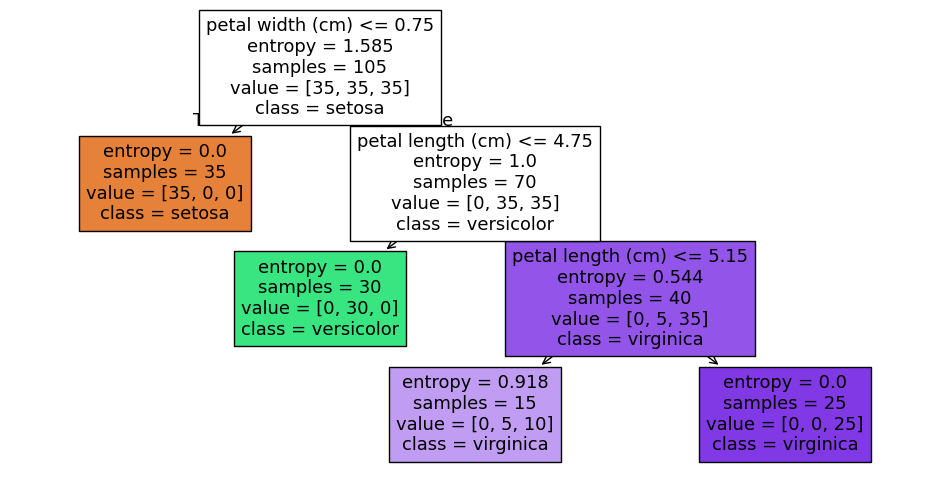

In [ ]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


max_depth= 1 | train accuracy=0.6667 | test accuracy=0.6667
max_depth= 2 | train accuracy=0.9524 | test accuracy=0.9556
max_depth= 3 | train accuracy=0.9524 | test accuracy=0.9556
max_depth= 4 | train accuracy=0.9524 | test accuracy=0.9333
max_depth= 5 | train accuracy=0.9714 | test accuracy=0.9778
max_depth= 6 | train accuracy=0.9810 | test accuracy=0.9778
max_depth= 7 | train accuracy=0.9810 | test accuracy=0.9778
max_depth= 8 | train accuracy=0.9905 | test accuracy=0.9778
max_depth= 9 | train accuracy=1.0000 | test accuracy=0.9778
max_depth=10 | train accuracy=1.0000 | test accuracy=0.9778
max_depth=11 | train accuracy=1.0000 | test accuracy=0.9778
max_depth=12 | train accuracy=1.0000 | test accuracy=0.9778
max_depth=13 | train accuracy=1.0000 | test accuracy=0.9778
max_depth=14 | train accuracy=1.0000 | test accuracy=0.9778
max_depth=15 | train accuracy=1.0000 | test accuracy=0.9778
Best test accuracy: 0.9778 at max_depth=5


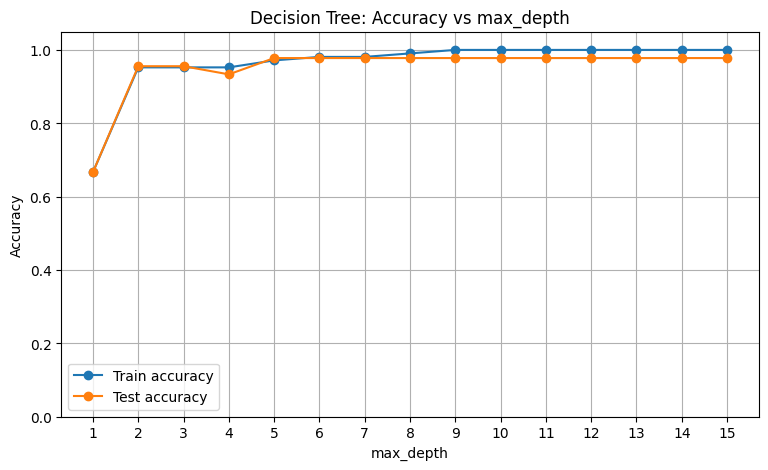

In [ ]:
depths = range(1, 16)
train_accuracies = []
test_accuracies = []

for depth in depths:
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    model.fit(X_train, y_train)
    train_accuracies.append(accuracy_score(y_train, model.predict(X_train)))
    test_accuracies.append(accuracy_score(y_test, model.predict(X_test)))

for depth, train_acc, test_acc in zip(depths, train_accuracies, test_accuracies):
    print(f'max_depth={depth:2d} | train accuracy={train_acc:.4f} | test accuracy={test_acc:.4f}')

best_index = int(np.argmax(test_accuracies))
print(f'Best test accuracy: {test_accuracies[best_index]:.4f} at max_depth={list(depths)[best_index]}')

plt.figure(figsize=(9, 5))
plt.plot(list(depths), train_accuracies, marker='o', label='Train accuracy')
plt.plot(list(depths), test_accuracies, marker='o', label='Test accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.xticks(list(depths))
plt.ylim(0, 1.05)
plt.title('Decision Tree: Accuracy vs max_depth')
plt.legend()
plt.grid(True)
plt.show()


**Answer:** In Week 6, polynomial degree played a similar role; in Week 7, the value of K in KNN controlled model complexity. If the model is too simple, it underfits. If it is too complex (for example, a very deep tree), it can overfit the training data. The best setting is chosen using validation/test performance, not training accuracy alone.


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [ ]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Decision Tree test accuracy: 0.8814814814814815
max_depth=3: test accuracy=0.5296
max_depth=6: test accuracy=0.8537
max_depth=10: test accuracy=0.8796


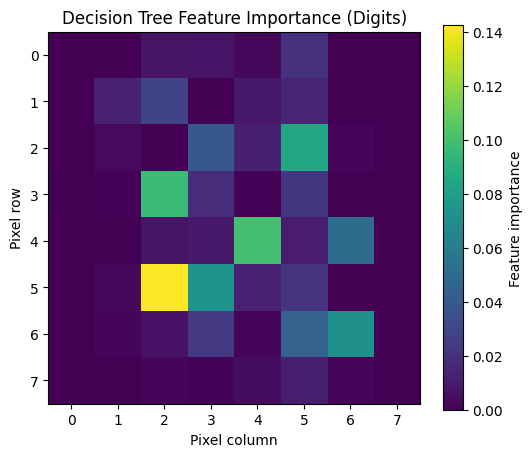

In [ ]:
digit_tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
digit_tree.fit(Xd_train, yd_train)
print('Decision Tree test accuracy:', accuracy_score(yd_test, digit_tree.predict(Xd_test)))

for depth in [3, 6, 10]:
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    model.fit(Xd_train, yd_train)
    print(f'max_depth={depth}: test accuracy={accuracy_score(yd_test, model.predict(Xd_test)):.4f}')

importance_image = digit_tree.feature_importances_.reshape(8, 8)
plt.figure(figsize=(6, 5))
plt.imshow(importance_image, cmap='viridis')
plt.colorbar(label='Feature importance')
plt.title('Decision Tree Feature Importance (Digits)')
plt.xlabel('Pixel column')
plt.ylabel('Pixel row')
plt.show()


**Answer:** The decision tree is less accurate than KNN on this split: the tree gets about 88.15%, while KNN gets about 97.96%. A tree makes a sequence of threshold-based splits and may not capture the digit patterns as effectively as KNN. The importance map highlights the pixels the tree uses most; pixels with low importance contribute little to its decisions.


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [ ]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [ ]:
text_tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
text_tree.fit(X_text, labels)

print(export_text(text_tree, feature_names=vocab))

test_sentences = [
    'the striker scored a goal',
    'I enjoy cricket but also pasta'
]
for sentence in test_sentences:
    vector = to_vector(sentence, vocab).reshape(1, -1)
    print(f'{sentence!r} -> {text_tree.predict(vector)[0]}')


|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

'the striker scored a goal' -> sports
'I enjoy cricket but also pasta' -> sports


**Answer:** No, the same split words are not guaranteed. With only six sentences, a few examples can strongly influence the tree's rules. Adding more examples may change the selected words and improve generalization. A tree trained on very little data should therefore be treated cautiously and evaluated on unseen examples.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
